# TF-MoDISco results

TF-MoDISco gathers the seqlets of a model's contribution scores, the short
stretches of high contribution, into patterns. Each pattern is a motif the
model relies on, described by the average scores of its seqlets. This guide
reads the TF-MoDISco results of a published model, names the patterns
against known motifs and finds where the model used them in one enhancer.

We use the chromBPNet model of ATAC-seq in K562 cells from the
[motifs and deep learning](deep-learning.ipynb) guide, which introduces
contribution scores. Reading TF-MoDISco results needs the `h5py` extra, and
reading bigWig files the `bigwig` extra.

In [1]:
import json
import pathlib
import tarfile
import urllib.request

import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need the model's TF-MoDISco results, the regions it was interpreted on and
the JASPAR 2024 collection of vertebrate motifs. The TF-MoDISco results come
as a 311 MB archive holding the patterns of both of the model's outputs. We
only unpack those of the counts output, which predicts how accessible each
region is:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

## The patterns

[`read_modisco()`][universalmotif.read_modisco] reads every pattern as a
contribution weight matrix (CWM). The CWM holds the average contribution of
each letter at each position of the pattern's seqlets. Patterns are trimmed
to the positions whose contribution is at least 30% of the highest. Their
names carry the accessions of the experiment and the model, which we shorten
to the group and the number:

In [3]:
def short_name(motif):
    group, _, name = motif.name.partition(".")
    return motif.replace(name=f"{group[:3]}_{name.rsplit('_', 1)[1]}")

cwms = [short_name(m) for m in um.read_modisco(modisco_path)]
pos = [m for m in cwms if m.name.startswith("pos")]
neg = [m for m in cwms if m.name.startswith("neg")]
print(len(pos), len(neg))
pl.DataFrame({
    "pattern": [m.name for m in cwms],
    "seqlets": [int(m.nsites) for m in cwms],
    "width": [m.width for m in cwms],
    "consensus": [m.consensus for m in cwms],
}).head(8)

44 16


pattern,seqlets,width,consensus
str,i64,i64,str
"""pos_0""",36546,5,"""GATAA"""
"""pos_1""",33538,14,"""CCACYAGGGGGCGS"""
"""pos_2""",27345,9,"""GCCCCGCCC"""
"""pos_3""",13390,10,"""GCTGAGTCAY"""
"""pos_4""",9410,7,"""CTTCCGG"""
"""pos_5""",6024,7,"""YGATTGG"""
"""pos_6""",4957,11,"""GCGCATGCGCR"""
"""pos_7""",4175,8,"""TTGCATCA"""


Positive patterns are made of bases that raised the model's prediction, and
negative patterns of bases that lowered it. Within each group, patterns are
ordered by their number of seqlets. The most common one is the short
`GATAA`, found over 36,000 times.

A CWM's logo shows how much each base mattered to the model, not how often
it was seen. The letters of negative patterns hang below zero. Here are the
first five positive patterns and the first two negative ones, all on the same
scale:

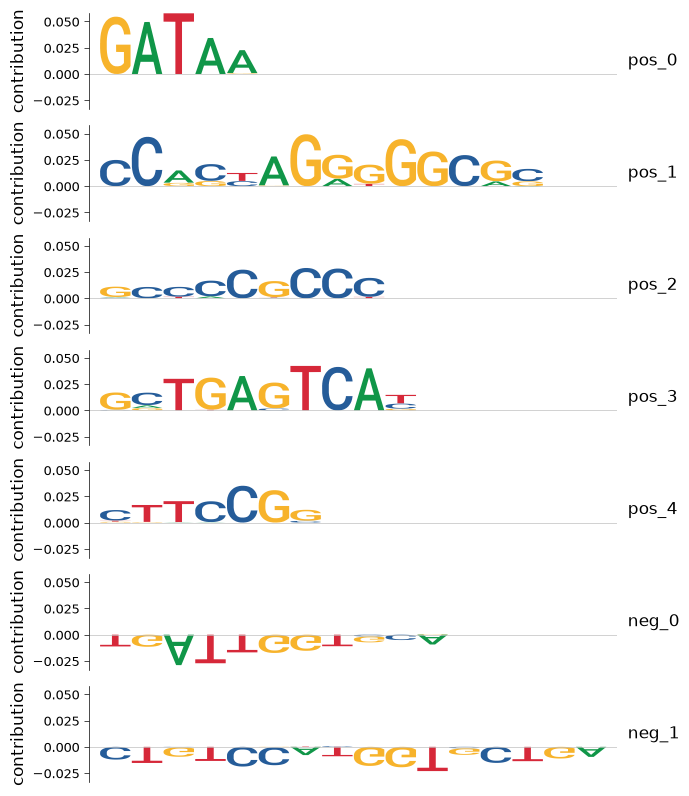

In [4]:
fig = um.view_motifs(pos[:5] + neg[:2], rc=False, align=False, names_pos="right",
                     show_positions=False, figsize=(7, 8))

## Naming the patterns

TF-MoDISco does not know which proteins bind its patterns, so the next step
is to match them to known motifs. Comparisons with a database work on letter
frequencies. With `type="PPM"`, `read_modisco()` gives each pattern as the
letter frequencies of its seqlets. We also trim less, keeping positions with
at least 20% of the highest contribution:

In [5]:
ppms = [short_name(m) for m in um.read_modisco(modisco_path, type="PPM", trim_threshold=0.2)]
print(pos[0].consensus, ppms[0].consensus)

GATAA KNNNNNNNNWGATAAG


At the default cutoff the first pattern is just `GATAA`. That is too short to
stand out against a database of nearly 900 motifs. The wider version keeps
enough of its flanks to be matched with confidence.

[`name_motifs()`][universalmotif.name_motifs] finds the database motifs each
pattern resembles most. It scores the whole of each pattern, as TOMTOM does,
and gives q-values corrected for the size of the database:

In [6]:
jaspar = um.read_meme(jaspar_path)
names = um.name_motifs(ppms, jaspar, top=3, nthreads=2)
best = names.filter(pl.col("rank") == 1).select(pattern="motif", tf="altname", qvalue="qvalue")
summary = pl.DataFrame({
    "pattern": [m.name for m in ppms],
    "seqlets": [int(m.nsites) for m in ppms],
    "consensus": [m.consensus for m in ppms],
}).join(best, on="pattern", how="left")
summary.head(20)

pattern,seqlets,consensus,tf,qvalue
str,i64,str,str,f64
"""pos_0""",36546,"""KNNNNNNNNWGATAAG""","""GATA2""",0.000972
"""pos_1""",33538,"""CCASYAGRKGGCRSY""","""CTCF""",1.5894e-8
"""pos_2""",27345,"""NGCCCCGCCCCC""","""KLF16""",0.00016
"""pos_3""",13390,"""GMTGAGTCAY""","""Bach1::Mafk""",0.000005
"""pos_4""",9410,"""NRCTTCCGG""","""ELK4""",1.2917e-7
"""pos_5""",6024,"""NNNYNCYSATTGGCYN""","""NFYA""",0.003269
"""pos_6""",4957,"""NGCGCNTGCGCN""","""Nrf1""",0.000186
"""pos_7""",4175,"""RTTGCATCAK""","""ATF4""",6.1207e-7
"""pos_8""",3682,"""NCACTTCCTSTTT""","""SPIB""",0.000008


Most of the common patterns match motifs of factors known to be active in
K562 cells. The GATA motif of `pos_0` is bound there by GATA1, a master
regulator of red blood cell development. `pos_3` and `pos_9` are the MAF
recognition element of NF-E2, another erythroid factor, which shares it with
BACH1, NRF2 and the small MAF proteins. Other patterns belong to factors found at
regulatory elements in most cell types, such as CTCF, SP and KLF, ETS, NF-Y,
NRF1, AP-1 and ATF.

The best match is only the closest motif in JASPAR. Factors of one family
often share a motif, so `KLF16` here stands for the SP and KLF families as a
whole. The negative patterns are next:

In [7]:
summary.filter(pl.col("pattern").str.starts_with("neg"))

pattern,seqlets,consensus,tf,qvalue
str,i64,str,str,f64
"""neg_0""",503,"""CTGATTGGTSCRT""","""NFYA""",0.007439
"""neg_1""",235,"""CTGTCCRTGGTGCTGAA""","""REST""",7.1160e-7
"""neg_2""",203,"""NNDNNNDNNWTGATKGATGSATNNATNN""","""PBX1""",0.039808
"""neg_3""",184,"""VDGNTGGCATCNN""",null,null
"""neg_4""",156,"""GYRTGGTGGYGBRCACCTGTART""","""SNAI2""",0.009635
"""neg_5""",148,"""NAGRTGGGCAYCN""",null,null
"""neg_6""",131,"""NNNNATCCATGATGVTNNNNNNN""",null,null
"""neg_7""",115,"""NNNNNNATGATGATSATGATGATGATGATG""",null,null
"""neg_8""",103,"""GATGAGATTTGGGTGGGGACA""","""KLF4""",0.04027


The negative patterns are much rarer, and fewer of them match a known motif.
The clearest is `neg_1`, the motif of REST. REST silences neuronal genes
outside the nervous system, so the model has learned that its sites make a
region less accessible. Others are harder to read, and some match nothing at
all.

[`plot_modisco()`][universalmotif.plot_modisco] draws the same summary in the
style of TF-MoDISco's own reports. Each row holds a pattern's number of
seqlets, its CWM, its letter frequencies as information content (ICM) and its
three best matches, turned to read the same way as the pattern. It takes the
table from `name_motifs()`. Here are the eight most common positive patterns
and three negative ones:

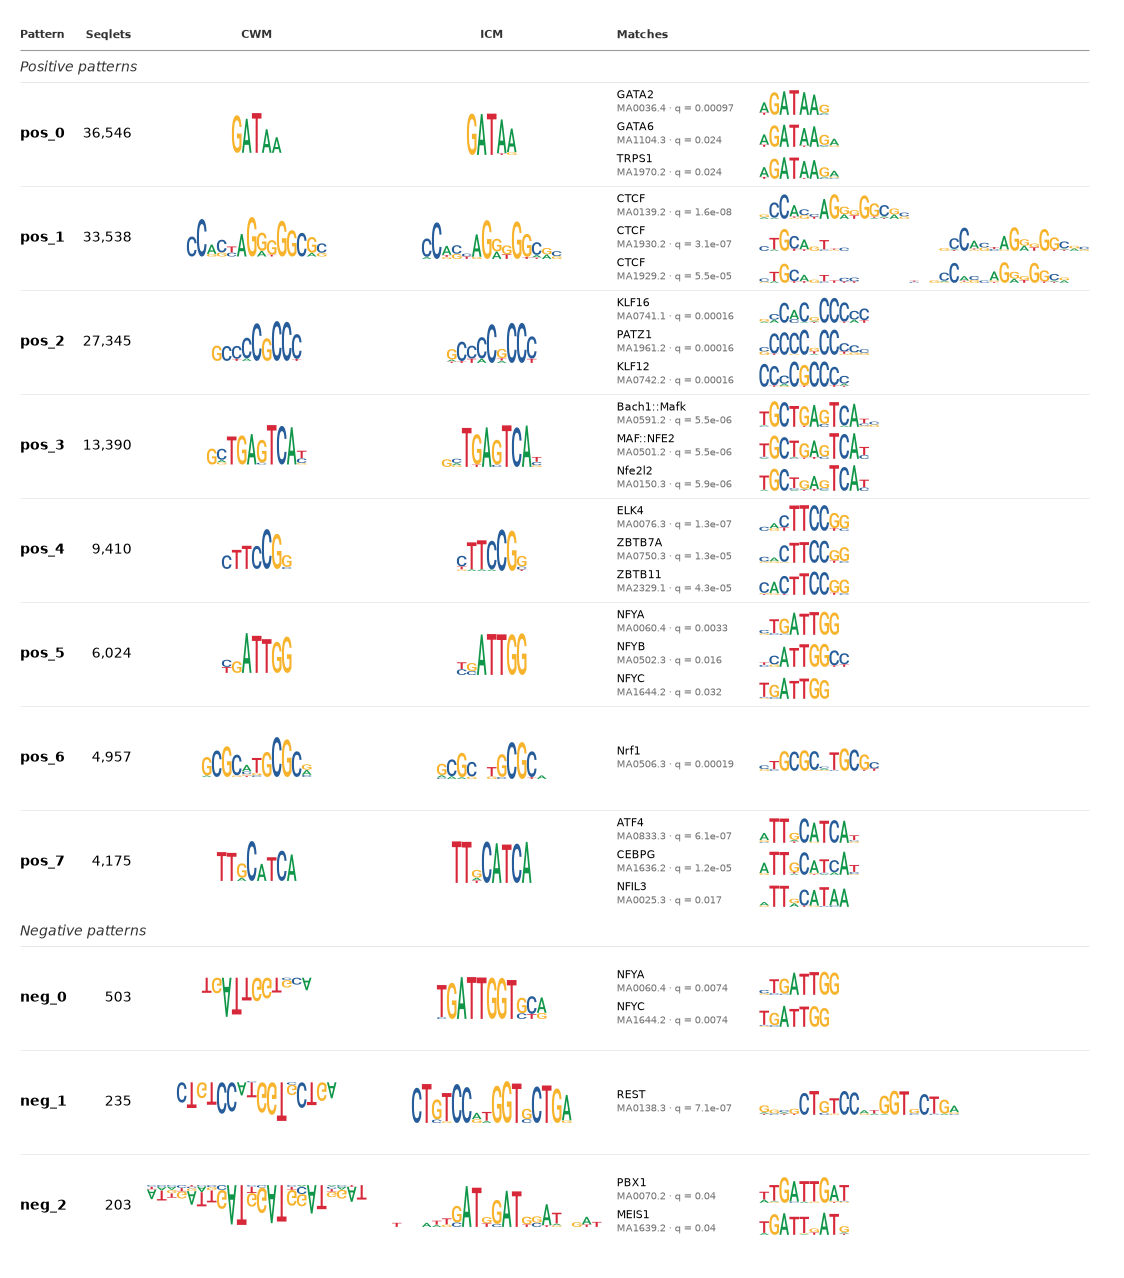

In [8]:
fig = um.plot_modisco(modisco_path, matches=names, database=jaspar, patterns=(8, 3))

The CWMs of the negative patterns point down, since their bases lowered the
prediction. Their letter frequencies read like those of any other motif.

## Redundant patterns

TF-MoDISco can split the seqlets of one motif between several patterns, as
with `pos_3` and `pos_9`. [`compare_motifs()`][universalmotif.compare_motifs]
compares CWMs by their cosine similarity, which keeps the sign and size of
their contributions. [`merge_similar()`][universalmotif.merge_similar] groups
the patterns whose cosine reaches 0.8. With complete linkage, every pattern
of a group is that similar to every other:

In [9]:
clusters = um.merge_similar(pos, return_clusters=True, linkage="complete", nthreads=2)
(
    clusters.join(summary.select(name="pattern", tf="tf"), on="name", how="left")
    .group_by("cluster", maintain_order=True)
    .agg("name", "tf")
    .filter(pl.col("name").list.len() > 1)
)

cluster,name,tf
i64,list[str],list[str]
0,"[""pos_0"", ""pos_36""]","[""GATA2"", null]"
1,"[""pos_1"", ""pos_19""]","[""CTCF"", ""CTCF""]"
2,"[""pos_2"", ""pos_22""]","[""KLF16"", ""SP2""]"
3,"[""pos_3"", ""pos_9""]","[""Bach1::Mafk"", ""Nfe2l2""]"
5,"[""pos_5"", ""pos_32""]","[""NFYA"", null]"
9,"[""pos_10"", ""pos_15""]","[""FOSL1::JUND"", ""TFEC""]"
12,"[""pos_13"", ""pos_27""]","[""YY2"", ""ZFP42""]"
14,"[""pos_16"", ""pos_30""]","[""ZBTB33"", ""ZBTB33""]"
27,"[""pos_34"", ""pos_40""]","[""POU2F3"", ""KLF4""]"


[`plot_comparison()`][universalmotif.plot_comparison] draws the scores behind
these groups next to the logos of the patterns. With `cut=0.8`, it marks
where the tree is cut and boxes each group:

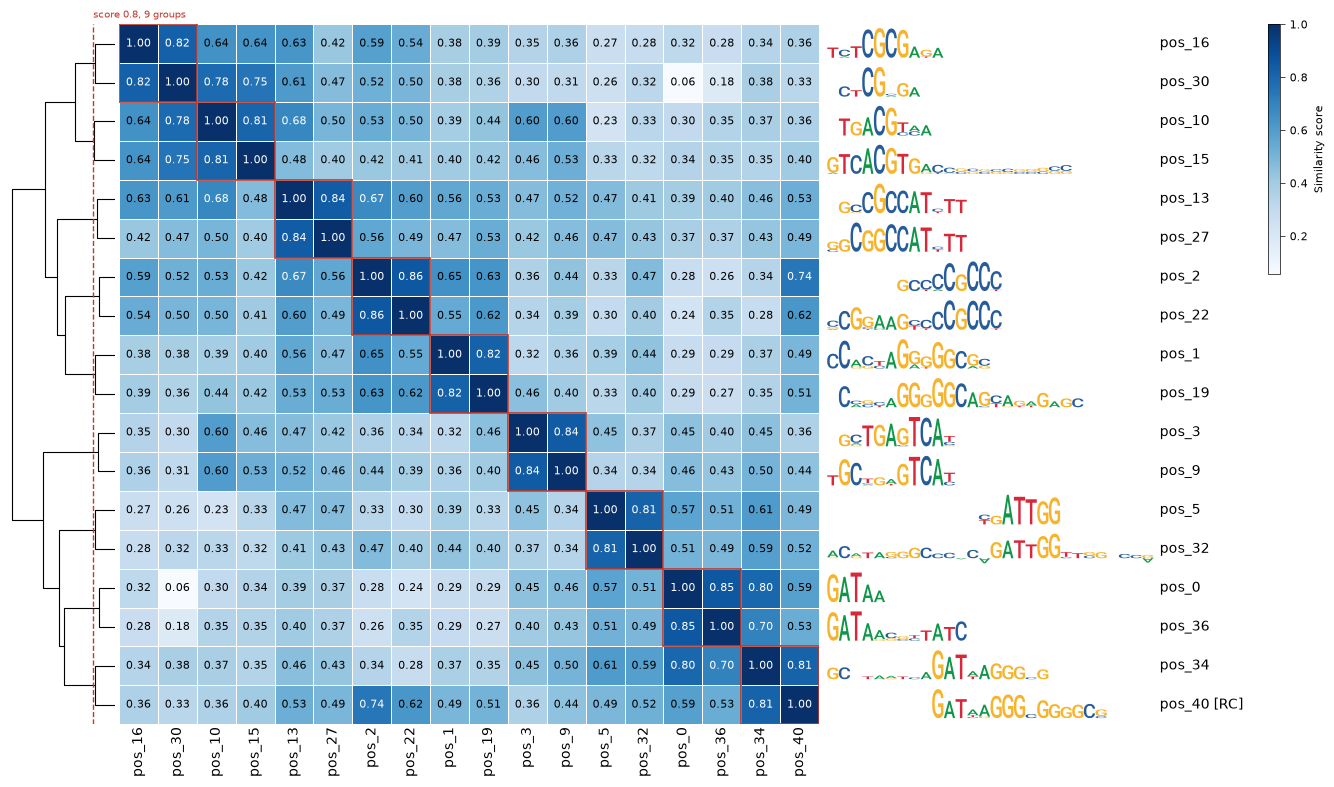

In [10]:
grouped = clusters.filter(pl.len().over("cluster") > 1)["name"].to_list()
fig = um.plot_comparison([m for m in pos if m.name in grouped], cut=0.8, nthreads=2)

Most of these pairs are one motif found twice, such as the two CTCF patterns
or the two MAF recognition elements. Others join a pattern to a wider one
that holds it, such as the NF-Y site of `pos_5` within `pos_32`. All of them
score between 0.81 and 0.86, so no cutoff separates the duplicates from the
rest. Groups like these are best checked by eye before they are merged.

## The seqlets of a pattern

A pattern is the average of its seqlets.
[`read_seqlets()`][universalmotif.read_seqlets] reads the seqlets of every
pattern as a table, here with the scores of the letters present.
[`plot_seqlets()`][universalmotif.plot_seqlets] draws the seqlets of one
pattern a row each. The contribution of each position is shown
as a colour on the left, and the letters on the right. Rows are sorted from
the strongest seqlet down, each read along the pattern:

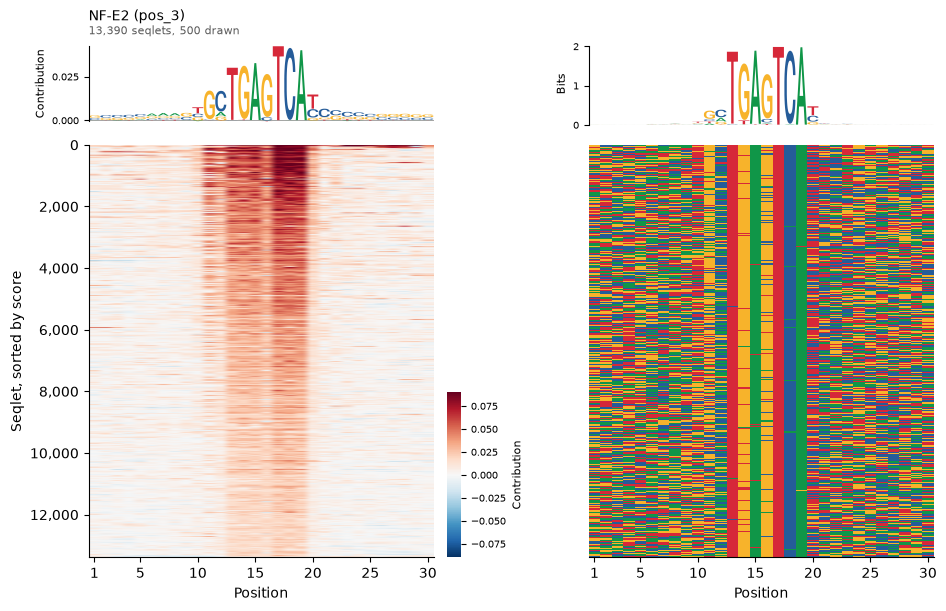

In [11]:
seqlets = um.read_seqlets(modisco_path, scores="projected")
seqlets = seqlets.with_columns(pl.col("motif").str.replace(r"^(pos|neg)_patterns\..*_(\d+)$", "${1}_${2}"))
fig = um.plot_seqlets(seqlets, "pos_3", title="NF-E2 (pos_3)")

The core `TGAGTCA` is the same in nearly every seqlet, while the letters
around it vary freely. Its contribution fades steadily from the strongest
seqlets to the weakest without changing shape, so the pattern is not an
average of distinct kinds of sites.

## Where the model used each pattern

A scan of the sequence finds the sites that look like a motif, whether or
not the model relied on them.
[`scan_contributions()`][universalmotif.scan_contributions] instead matches
the CWMs against the contribution scores, so it finds the sites the model
used. Each window is scored in two ways:

- its similarity, the cosine between its scores and the CWM;
- its importance, the sum of its absolute scores.

Both must reach the pattern's thresholds.
[`modisco_thresholds()`][universalmotif.modisco_thresholds] sets these for
each pattern from its own seqlets, since patterns differ a great deal in how
alike their seqlets are.

We use the HS2 enhancer of the β-globin locus from the
[overview](deep-learning.ipynb). Its scores are read from ENCODE's bigWig
track and its sequence from the UCSC Genome Browser:

In [12]:
regions = um.read_bed(regions_path)
row, chrom, start, end = regions.with_row_index().filter(
    pl.col("chrom") == "chr11", pl.col("start") <= 5_280_600, pl.col("end") >= 5_280_900,
).row(0)
scores = um.signal_values(f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig", chrom, start, end)
url = f"https://api.genome.ucsc.edu/getData/sequence?genome=hg38;chrom={chrom};start={start};end={end}"
with urllib.request.urlopen(url) as response:
    seq = json.load(response)["dna"].upper()

The track holds the score of the base in the genome at each position, so the
sequence is given too. Overlapping hits of different patterns are removed,
keeping the best:

In [13]:
thresholds = um.modisco_thresholds(modisco_path).with_columns(
    pl.col("motif").str.replace(r"^(pos|neg)_patterns\..*_(\d+)$", "${1}_${2}")
)
labels = dict(best.select("pattern", "tf").iter_rows())
hits = um.scan_contributions(cwms, scores, sequences=seq, thresholds=thresholds, no_overlaps_across_motifs=True)
hits = hits.with_columns(tf=pl.col("motif").replace(labels)).sort("start")
hits.select("motif", "tf", "start", "end", "strand", "match", "similarity", "importance")

motif,tf,start,end,strand,match,similarity,importance
str,str,i64,i64,str,str,f64,f64
"""pos_0""","""GATA2""",370,375,"""+""","""GATAG""",0.965962,0.118935
"""pos_20""","""pos_20""",375,395,"""-""","""TCAGCCTAGAGTGATGACTC""",0.397491,0.171823
"""neg_3""","""neg_3""",401,410,"""+""","""CTGGGCACA""",0.777879,0.080235
"""pos_3""","""Bach1::Mafk""",426,436,"""-""","""GATGAGTCAT""",0.975255,0.819061
"""pos_3""","""Bach1::Mafk""",436,446,"""-""","""GCTGAGTCAT""",0.963694,0.94751
"""pos_6""","""Nrf1""",452,463,"""+""","""GTGCTTGAGCC""",0.72435,0.108908
"""pos_25""","""KLF5""",495,514,"""-""","""GTGCCCCACCCCCGCCTTC""",0.681867,0.345554


Given the CWMs, `view_attributions()` draws each hit's pattern above it,
turned to read along the hit. The hits are labelled with their best matches
through a `label` column:

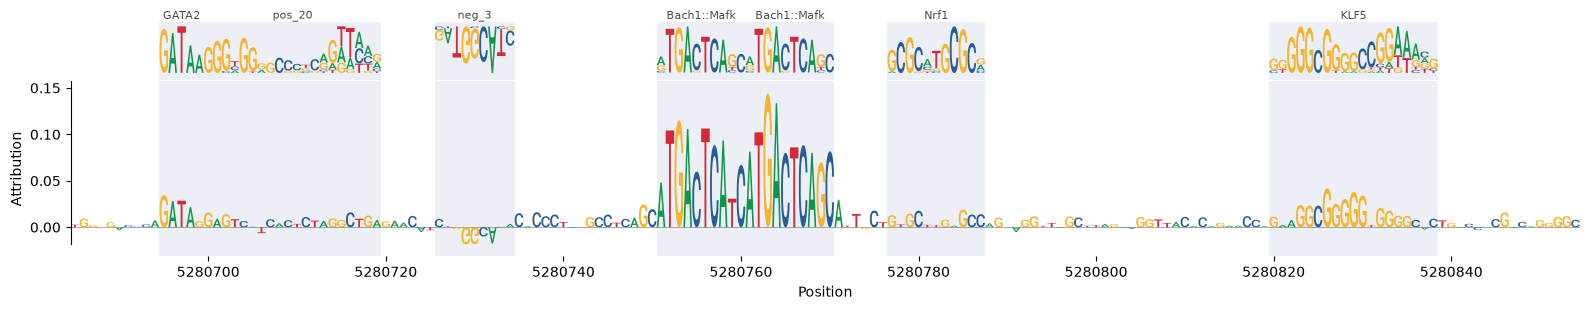

In [14]:
ax = um.view_attributions(
    scores, seq, start=start, region=(start + 360, start + 530),
    hits=hits.with_columns(label=pl.col("tf")), motifs=cwms,
)

Besides the tandem NF-E2 sites and the GC-rich site to their right, this
finds the `AGATAG` GATA site that a scan of the sequence misses. Its letters
are a poor match to the GATA motif, but the model gave them the shape and
weight of a typical GATA seqlet. Weaker hits come too, such as one of
`pos_20` over the faint scores just past the GATA site. The seqlets of
`pos_20` vary so much that its similarity threshold is only about 0.4. Hits
like this one are worth checking against the scores before they are taken at
face value.